# 04 · Priors de M1 y M2 y chequeo predictivo a priori
**Grupo 2 · Estadística Bayesiana · Entrega final**  
Jean Paul Rojas Rojas · Daniel Estiven Pacheco Villagrande · Diego Andrés Cascante Camacho

**Qué hace.** Simula 4.000 ciudades solo con las priors de M1 y M2 y los tamaños reales de las celdas de 2015–2017, y compara cuatro estadísticos con lo observado (Figura 5 del informe).

**Entradas.** `datos/siniestros_limpios.csv`.

**Salidas.** `salidas/figuras/prior_predictivo.png`; `salidas/resultados/04_priors.json`.

*Respaldo por etapas: el notebook principal es `../Grupo2_Bayesiana_completo.ipynb`, que reúne estas ocho etapas.* Orden de ejecución y trazabilidad completa: `../README.md`.

In [1]:
# Configuración: funciona en Google Colab y en un computador
# En Colab: suba la carpeta "notebooks" a su Drive. Si el buscador automático no la encuentra,
# escriba su ruta en BASE_COLAB, p. ej. '/content/drive/MyDrive/Grupo2_EntregaFinal_Bayesiana/notebooks'
BASE_COLAB = ''
import os, sys, glob
from pathlib import Path
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    if not BASE_COLAB:
        cand = glob.glob('/content/drive/MyDrive/**/notebooks/comun.py', recursive=True)
        assert cand, 'No encontré la carpeta notebooks en su Drive: escriba su ruta en BASE_COLAB'
        BASE_COLAB = os.path.dirname(cand[0])
    BASE = Path(BASE_COLAB)
else:
    # el notebook puede estar en notebooks/ o en notebooks/por_etapas/
    BASE = Path.cwd() if (Path.cwd() / 'comun.py').exists() else Path.cwd().parent
os.chdir(BASE)
sys.path.insert(0, str(BASE))
import numpy, pandas, scipy, matplotlib
print('Carpeta:', BASE)
print('Python', sys.version.split()[0], '| numpy', numpy.__version__, '| pandas', pandas.__version__,
      '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)

Carpeta: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks
Python 3.12.10 | numpy 2.3.5 | pandas 2.3.3 | scipy 1.18.1 | matplotlib 3.10.7


## Priors (Tabla 1 del informe)
| Parámetro | Prior | Argumento |
|---|---|---|
| $m$ | Beta(2, 4) | Media 1/3; débilmente informada por Vergel-Tovar et al. (2020), ≈30 % con víctimas |
| $\kappa$ | Gamma(2; 0,04) | Media 50: cuántos siniestros "presta" la ciudad a cada celda |
| $\mu$ | N(logit 1/3, 1) | Mismo centro que $m$ en escala logit |
| $\sigma_a^2, \sigma_b^2$ | IG(3; 0,5) | Media 0,25: localidad o franja típica a ±11 puntos del centro |
| $\sigma_g^2$ | IG(3; 0,1) | Interacción menor que los efectos principales |
| $\sigma_d^2$ | IG(3; 0,05) | El nivel anual varía pocos puntos |

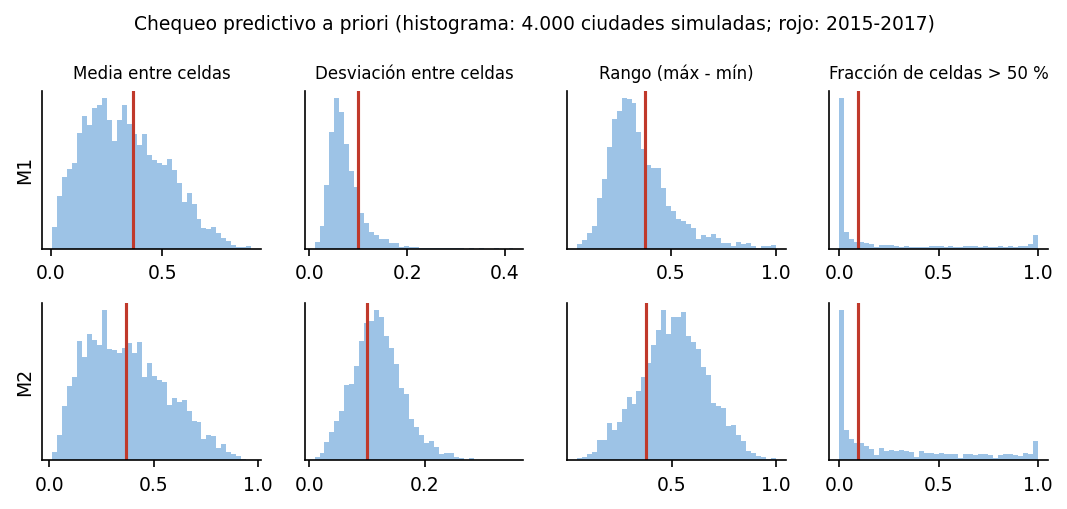

Guardado: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks\salidas\resultados\04_priors.json


In [2]:
from comun import *
from mcmc import M0, S0, IG
R = {}
# ---------------------------------------------------------------------------
# 7. Chequeo predictivo a priori (M1 y M2)
# ---------------------------------------------------------------------------
def stats_celdas(yc, nc):
    m_ = nc >= 30
    pr = yc[..., m_] / nc[m_]
    return np.stack([pr.mean(-1), pr.std(-1), pr.max(-1) - pr.min(-1), (pr > 0.5).mean(-1)], -1)


rng = np.random.default_rng(SEED + 7)
S = 4000
mpri = rng.beta(2, 4, S)
kpri = rng.gamma(2, 1 / 0.04, S)
tpri = rng.beta((mpri * kpri)[:, None], ((1 - mpri) * kpri)[:, None], (S, L * F))
st_m1 = stats_celdas(rng.binomial(n_tr, tpri), n_tr)

cy = (tr.groupby(["localidad", "franja", "anio"]).grave.agg(n="size", y="sum")
      .reindex(pd.MultiIndex.from_product([LOCS, FRANJAS, [2015, 2016, 2017]]), fill_value=0))
N3 = cy["n"].values.reshape(L, F, 3)
Y3 = cy["y"].values.reshape(L, F, 3)


def ig(a0, b0, size):
    return 1 / rng.gamma(a0, 1 / b0, size)


mu_p = rng.normal(M0, S0, S)
eta_pri = (mu_p[:, None, None, None]
           + np.sqrt(ig(*IG["a"], S))[:, None, None, None] * rng.standard_normal((S, L, 1, 1))
           + np.sqrt(ig(*IG["b"], S))[:, None, None, None] * rng.standard_normal((S, 1, F, 1))
           + np.sqrt(ig(*IG["g"], S))[:, None, None, None] * rng.standard_normal((S, L, F, 1))
           + np.sqrt(ig(*IG["d"], S))[:, None, None, None] * rng.standard_normal((S, 1, 1, 3)))
y2 = rng.binomial(N3[None], sp.expit(eta_pri)).sum(-1).reshape(S, -1)
st_m2 = stats_celdas(y2, n_tr)
st_obs = stats_celdas(y_tr[None], n_tr)[0]
nombres = ["Media entre celdas", "Desviación entre celdas", "Rango (máx - mín)", "Fracción de celdas > 50 %"]
fig, axs = plt.subplots(2, 4, figsize=(7.2, 3.4))
ppc = {}
for fila, (stt, nom) in enumerate(((st_m1, "M1"), (st_m2, "M2"))):
    for j in range(4):
        ax = axs[fila, j]
        ax.hist(stt[:, j], bins=40, color="#9dc3e6")
        ax.axvline(st_obs[j], color=ROJO)
        ax.set_yticks([])
        if fila == 0:
            ax.set_title(nombres[j], fontsize=8)
        if j == 0:
            ax.set_ylabel(nom)
        ppc[f"{nom}_{j}"] = float((stt[:, j] < st_obs[j]).mean())
fig.suptitle("Chequeo predictivo a priori (histograma: 4.000 ciudades simuladas; rojo: 2015-2017)", fontsize=9)
fig.tight_layout()
fig.savefig(FIG / "prior_predictivo.png")
plt.show()
R["ppc_percentil"] = ppc
R["ppc_obs"] = st_obs.tolist()
guardar_json(R, '04_priors.json')